# Chapter 7 — Unsupervised Learning
**Sumber:** *Practical Statistics for Data Scientists*, 2nd Ed. (Bruce, Bruce & Gedeck, O'Reilly)

Notebook ini mereproduksi kode Python dari Chapter 7 dan menjelaskan teori di baliknya.

**Tujuan chapter:** *Unsupervised learning* adalah kumpulan metode statistik yang mengekstrak makna dari data **tanpa** melatih model pada data berlabel (tidak ada variabel outcome $Y$ yang ingin diprediksi). Tujuannya bisa berupa:
- **Reduksi dimensi**: meringkas banyak variabel menjadi sedikit variabel baru yang tetap memuat sebagian besar informasi (*Principal Components Analysis*, *Correspondence Analysis*).
- **Clustering**: mengelompokkan record ke dalam kelompok-kelompok yang mirip (*K-Means*, *Hierarchical Clustering*, *Model-Based Clustering*).
- **Eksplorasi**: memahami struktur data sebelum membangun model prediktif, misalnya untuk mendefinisikan segmen pelanggan atau mendeteksi pola.

Unsupervised learning juga bisa menjadi **langkah pra-pemrosesan** untuk supervised learning (misalnya memakai komponen utama sebagai prediktor, atau membangun model terpisah per cluster). Chapter ini juga membahas isu praktis: **penskalaan variabel**, **variabel dominan**, dan **data campuran (numerik + kategorikal)** dengan *Gower's distance*.

## Import Library

In [1]:
import math
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np

from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import multivariate_normal

import prince                      # Correspondence Analysis
from adjustText import adjust_text # merapikan label teks pada plot

import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

In [2]:
%matplotlib inline

In [3]:
# Lokasi folder data (folder `data/` berada satu level di atas folder `notebooks/`)
DATA = Path('../data')
if not DATA.exists():          # cadangan jika notebook dijalankan dari root repo
    DATA = Path('data')
print('Folder data ditemukan:', DATA.resolve().exists())

Folder data ditemukan: True


## Definisi Path Dataset

In [4]:
SP500_DATA_CSV = DATA / 'sp500_data.csv.gz'
SP500_SECTORS_CSV = DATA / 'sp500_sectors.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
HOUSE_TASKS_CSV = DATA / 'housetasks.csv'

## 7.1 Principal Components Analysis (PCA)

**Teori:** Sering kali variabel-variabel dalam data **saling berkorelasi** (bergerak bersama), sehingga sebagian informasinya redundan. **Principal Components Analysis (PCA)** adalah teknik untuk menemukan cara variabel numerik *covary* (bervariasi bersama), lalu menggabungkannya menjadi sejumlah kecil variabel baru yang disebut **principal components (PC)**.

Istilah kunci:
- **Principal component**: kombinasi linear dari variabel prediktor.
- **Loadings** (bobot): koefisien yang mengubah variabel asli menjadi komponen.
- **Screeplot**: plot varians tiap komponen, menunjukkan kepentingan relatifnya (baik sebagai varians maupun proporsi varians yang dijelaskan).

Untuk $p$ variabel $X_1, \dots, X_p$, komponen utama ke-$j$ adalah
$$Z_j = w_{j,1}X_1 + w_{j,2}X_2 + \dots + w_{j,p}X_p$$
dengan bobot $w_j$ (vektor satuan, $\lVert w_j \rVert = 1$) dipilih agar:
1. $Z_1$ memiliki **varians sebesar mungkin** (menjelaskan variabilitas total sebanyak mungkin);
2. $Z_2$ memiliki varians terbesar berikutnya dengan syarat **tidak berkorelasi** (ortogonal) dengan $Z_1$; dan seterusnya.

Secara matematis, bobot-bobot ini adalah **eigenvector** dari matriks kovarians $\Sigma$ data (yang sudah di-*center*), dan varians tiap komponen adalah **eigenvalue**-nya:
$$\Sigma\, w_j = \lambda_j w_j, \qquad \operatorname{Var}(Z_j) = \lambda_j,\quad \lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_p .$$
Secara praktis, PCA dihitung lewat *singular value decomposition* (SVD) dari matriks data. Proporsi varians yang dijelaskan komponen ke-$j$ adalah $\lambda_j / \sum_k \lambda_k$.

PCA dikembangkan oleh Karl Pearson (1901) dan menjadi salah satu teknik unsupervised paling luas dipakai.

### 7.1.1 A Simple Example

**Teori:** Contoh paling sederhana memakai dua variabel: *return* harian saham **Chevron (CVX)** dan **ExxonMobil (XOM)**. Keduanya perusahaan minyak, sehingga return hariannya sangat berkorelasi. Dengan 2 variabel, PCA menghasilkan 2 komponen:
- **PC1** searah dengan "diagonal" sebaran data, yaitu arah variabilitas terbesar (kedua saham naik/turun bersama).
- **PC2** tegak lurus terhadap PC1, yaitu arah di mana kedua saham *menyimpang* satu sama lain.

Di `scikit-learn`, `PCA.components_` berisi loadings (satu baris per komponen). Tanda (+/−) loadings bersifat arbitrer: membalik tanda seluruh komponen tidak mengubah maknanya.

In [5]:
sp500_px = pd.read_csv(SP500_DATA_CSV, index_col=0)
oil_px = sp500_px[['XOM', 'CVX']]
print(oil_px.head())

                 XOM       CVX
1993-01-29 -0.016991  0.072921
1993-02-01  0.016991  0.102089
1993-02-02  0.084954  0.029168
1993-02-03  0.067964  0.058337
1993-02-04  0.034378  0.044272


In [6]:
pcs = PCA(n_components=2)
pcs.fit(oil_px)
loadings = pd.DataFrame(pcs.components_, columns=oil_px.columns)
print(loadings)
print('\nVarians tiap komponen      :', pcs.explained_variance_.round(4))
print('Proporsi varians dijelaskan:', pcs.explained_variance_ratio_.round(4))

        XOM       CVX
0  0.664711  0.747101
1  0.747101 -0.664711

Varians tiap komponen      : [0.7782 0.0905]
Proporsi varians dijelaskan: [0.8959 0.1041]


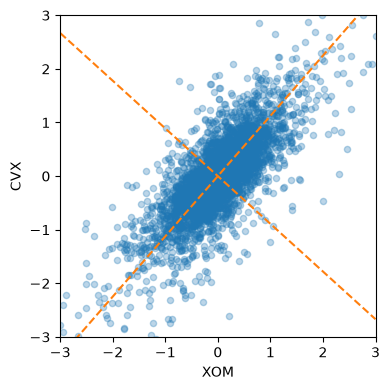

In [7]:
def abline(slope, intercept, ax):
    # Hitung koordinat garis berdasarkan slope dan intercept
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)

ax = oil_px.plot.scatter(x='XOM', y='CVX', alpha=0.3, figsize=(4, 4))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.plot(*abline(loadings.loc[0, 'CVX'] / loadings.loc[0, 'XOM'], 0, ax),
        '--', color='C1')
ax.plot(*abline(loadings.loc[1, 'CVX'] / loadings.loc[1, 'XOM'], 0, ax),
        '--', color='C1')

plt.tight_layout()
plt.show()

**Interpretasi:** Loadings PC1 adalah (XOM = 0.665, CVX = 0.747): kedua bobot positif dan hampir sama besar, sehingga PC1 pada dasarnya adalah **rata-rata return kedua saham minyak**, yaitu "faktor sektor energi" yang menggerakkan keduanya bersamaan. Loadings PC2 adalah (0.747, −0.665): bobot berlawanan tanda, sehingga PC2 mengukur **selisih** pergerakan CVX dan XOM (hari ketika keduanya menyimpang). PC1 menjelaskan **89.6%** varians total (varians 0.778), sedangkan PC2 hanya **10.4%** (varians 0.091). Pada scatter plot, garis putus-putus pertama mengikuti sumbu panjang awan titik yang miring ke kanan atas, dan garis kedua tegak lurus terhadapnya. Ini sesuai dengan korelasi tinggi antara XOM dan CVX.

### 7.1.2 Computing the Principal Components

**Teori:** Langkah-langkah menghitung PCA secara umum:
1. **Center** setiap variabel (kurangi rata-ratanya). Jika skala variabel berbeda, **standardisasi** juga (bagi dengan simpangan baku), sehingga yang dianalisis adalah matriks **korelasi**, bukan kovarians.
2. Komponen pertama adalah kombinasi linear yang memaksimalkan varians total yang dijelaskan.
3. Komponen berikutnya memakai variabel yang sama dengan bobot berbeda, memaksimalkan varians sisa, dan tidak berkorelasi dengan komponen sebelumnya.
4. Ulangi hingga diperoleh komponen sebanyak yang diinginkan (maksimum $p$).
5. **Skor** komponen untuk tiap record: $z_{ij} = \sum_k w_{j,k}\,(x_{ik} - \bar x_k)$; di `scikit-learn` diperoleh lewat `pca.transform(X)`.

`sklearn.decomposition.PCA` otomatis melakukan *centering*, tetapi **tidak** melakukan *scaling*; untuk itu gunakan `StandardScaler` terlebih dahulu bila perlu. Bobot di `components_` dan varians di `explained_variance_` adalah keluaran utamanya. Komponen utama juga bisa dipakai sebagai input model supervised (*principal components regression*) untuk mengurangi dimensi dan masalah multikolinearitas.

In [8]:
# Verifikasi manual: loadings PCA = eigenvector matriks kovarians
cov = np.cov(oil_px.to_numpy().T)
eigval, eigvec = np.linalg.eigh(cov)
order = np.argsort(eigval)[::-1]
print('Eigenvalue (urut menurun):', eigval[order].round(4))
print('Eigenvector (kolom = komponen):')
print(pd.DataFrame(eigvec[:, order], index=oil_px.columns, columns=['PC1', 'PC2']).round(4))

# Skor komponen untuk 5 record pertama
scores = pd.DataFrame(pcs.transform(oil_px), columns=['PC1', 'PC2'], index=oil_px.index)
print('\nSkor komponen (5 hari pertama):')
print(scores.head())

Eigenvalue (urut menurun): [0.7782 0.0905]
Eigenvector (kolom = komponen):
        PC1     PC2
XOM  0.6647 -0.7471
CVX  0.7471  0.6647

Skor komponen (5 hari pertama):
                 PC1       PC2
1993-01-29  0.027666 -0.072611
1993-02-01  0.072046 -0.066612
1993-02-02  0.062743  0.032635
1993-02-03  0.073241  0.000552
1993-02-04  0.040408 -0.015190


**Interpretasi:** Eigen-dekomposisi manual matriks kovarians menghasilkan eigenvalue **0.7782** dan **0.0905**, persis sama dengan `explained_variance_` dari `scikit-learn`. Eigenvector-nya juga sama dengan loadings (PC1 = (0.6647, 0.7471)); hanya tanda PC2 yang terbalik (−0.7471, 0.6647), yang membuktikan bahwa **tanda loadings bersifat arbitrer**. Skor komponen untuk hari pertama (29-01-1993) adalah PC1 = 0.028 dan PC2 = −0.073. Nilai PC2 yang negatif berarti hari itu CVX naik jauh lebih besar (0.073) daripada XOM (−0.017).

### 7.1.3 Interpreting Principal Components

**Teori:** Dua alat visual utama untuk menafsirkan PCA:
- **Screeplot**: bar/line plot dari varians (eigenvalue) tiap komponen. Kita mencari titik di mana varians turun tajam lalu melandai ("siku"), yaitu komponen-komponen awal yang menjelaskan sebagian besar variabilitas. Komponen sesudah siku umumnya dianggap *noise*.
- **Plot loadings**: menampilkan bobot tiap variabel pada beberapa komponen teratas. Variabel dengan loading besar (positif atau negatif) adalah yang paling "membentuk" komponen tersebut. Kelompok variabel yang loadings-nya bertanda sama dan besar menunjukkan variabel yang bergerak bersama.

Contoh di buku memakai return harian 16 saham besar dari berbagai sektor (teknologi, energi, keuangan, ritel) sejak 2011. Biasanya **PC1** adalah "faktor pasar" (semua saham bergerak searah), sedangkan PC berikutnya menangkap kontras antar sektor.

Cara memilih jumlah komponen: lihat screeplot (siku), pilih komponen yang menjelaskan proporsi kumulatif varians tertentu (misalnya 80–90%), atau pilih berdasarkan interpretabilitas. Bila komponen dipakai sebagai prediktor, jumlah komponen dapat dipilih dengan cross-validation.

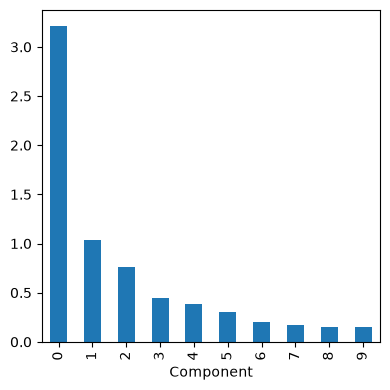

Proporsi varians (5 komponen pertama): [0.445 0.143 0.105 0.062 0.053]
Proporsi kumulatif                    : [0.445 0.588 0.693 0.755 0.809]


In [9]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
        'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]

sp_pca = PCA()
sp_pca.fit(top_sp)

explained_variance = pd.DataFrame(sp_pca.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')

plt.tight_layout()
plt.show()

print('Proporsi varians (5 komponen pertama):', sp_pca.explained_variance_ratio_[:5].round(3))
print('Proporsi kumulatif                    :', np.cumsum(sp_pca.explained_variance_ratio_[:5]).round(3))

In [10]:
loadings = pd.DataFrame(sp_pca.components_[0:5, :],
                        columns=top_sp.columns)
print(loadings.round(3))

    AAPL    AXP    COP   COST   CSCO    CVX     HD   INTC    JPM   MSFT  \
0  0.301  0.246  0.262  0.274  0.064  0.444  0.208  0.077  0.196  0.105   
1  0.505  0.139 -0.174  0.416  0.032 -0.289  0.278  0.034  0.041  0.054   
2  0.787 -0.135  0.002 -0.466  0.008 -0.082 -0.166  0.004 -0.062 -0.016   
3 -0.121  0.062 -0.206  0.093  0.004 -0.578  0.163 -0.002  0.058 -0.013   
4 -0.112  0.597  0.006 -0.556  0.040 -0.109  0.185  0.072  0.385  0.077   

     SLB    TGT    USB    WFC    WMT    XOM  
0  0.482  0.149  0.116  0.146  0.122  0.318  
1 -0.472  0.228  0.055  0.047  0.223 -0.154  
2  0.195 -0.161 -0.049 -0.042 -0.176 -0.090  
3  0.681  0.110  0.017  0.019  0.058 -0.295  
4 -0.181  0.056  0.155  0.216 -0.092 -0.013  


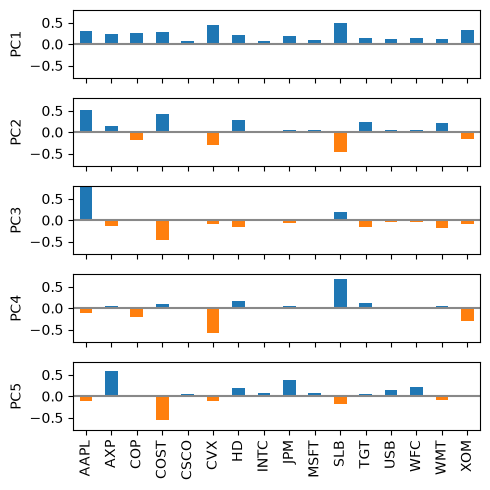

In [11]:
maxPC = 1.01 * loadings.loc[0:5, :].abs().to_numpy().max()

f, axes = plt.subplots(5, 1, figsize=(5, 5), sharex=True)

for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ['C0' if l > 0 else 'C1' for l in pc_loadings]
    ax.axhline(color='#888888')
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-maxPC, maxPC)

plt.tight_layout()
plt.show()

**Interpretasi:** Screeplot menunjukkan komponen pertama jauh lebih besar dari yang lain: PC1 menjelaskan **44.5%** varians, PC2 **14.3%**, PC3 **10.5%**, lalu PC4 dan PC5 hanya sekitar 6% dan 5%. Lima komponen pertama secara kumulatif menjelaskan **80.9%** varians. Interpretasi loadings:
- **PC1**: semua loading **positif** (0.06–0.48), jadi PC1 adalah **faktor pasar**: semua saham cenderung naik/turun bersama. Bobot terbesar ada pada saham energi (SLB 0.48, CVX 0.44, XOM 0.32) karena volatilitasnya lebih tinggi.
- **PC2**: kontras antara saham **energi** (CVX −0.29, SLB −0.47, COP −0.17, XOM −0.15) dan saham non-energi seperti AAPL (0.51), COST (0.42), HD, dan TGT. PC2 menangkap pergerakan sektor energi yang berlawanan dengan pasar lainnya.
- **PC3**: didominasi **AAPL (0.79)** yang dikontraskan dengan COST (−0.47), yaitu pergerakan khas Apple.
- **PC4**: SLB (0.68) vs CVX (−0.58) dan XOM (−0.30), yaitu kontras **di dalam** sektor energi (jasa minyak vs produsen minyak).
- **PC5**: AXP (0.60) dan JPM (0.39) vs COST (−0.56), yaitu kontras sektor keuangan vs ritel.

Komponen-komponen setelah PC2 semakin sulit ditafsirkan dan lebih menggambarkan perilaku saham individual.

### 7.1.4 Correspondence Analysis

**Teori:** PCA tidak bisa langsung dipakai untuk data **kategorikal**. Teknik serupa untuk data kategorikal adalah **Correspondence Analysis (CA)**. Tujuannya adalah mengenali asosiasi antar kategori, atau antara fitur kategorikal, pada sebuah **tabel kontingensi** (*two-way table*).

Ide dasarnya:
1. Ubah tabel frekuensi $N$ (ukuran $I \times J$) menjadi proporsi $P = N/n$, dengan massa baris $r_i$ dan massa kolom $c_j$.
2. Hitung matriks **residual standar** (berbasis statistik chi-square):
$$S_{ij} = \frac{p_{ij} - r_i c_j}{\sqrt{r_i c_j}}$$
yaitu deviasi frekuensi teramati dari frekuensi yang diharapkan bila baris dan kolom **independen**.
3. Lakukan SVD: $S = U \Lambda V^\top$. Koordinat utama baris adalah $F = D_r^{-1/2} U \Lambda$ dan koordinat kolom $G = D_c^{-1/2} V \Lambda$.
4. Plot baris dan kolom dalam satu grafik (**biplot**). Total "inersia" $= \chi^2/n$ dan dibagi ke dimensi-dimensi menurut $\lambda_k^2$.

Interpretasi: kategori baris dan kolom yang **berdekatan** di biplot cenderung **berasosiasi** (muncul bersama lebih sering dari yang diharapkan). Titik dekat titik asal menunjukkan profil yang mendekati rata-rata.

**Data:** `housetasks.csv` adalah tabel kontingensi tentang **siapa yang mengerjakan tugas rumah tangga** (baris: tugas seperti *Laundry*, *Repairs*; kolom: *Wife*, *Alternating*, *Husband*, *Jointly*). Kode memakai paket `prince` (versi baru: kolom koordinat bernama `0`, `1`).

           Wife  Alternating  Husband  Jointly
Task                                          
Laundry     156           14        2        4
Main_meal   124           20        5        4
Dinner       77           11        7       13
Breakfast    82           36       15        7
Tidying      53           11        1       57
Dishes       32           24        4       53
Shopping     33           23        9       55
Official     12           46       23       15
Driving      10           51       75        3
Finances     13           13       21       66
Insurance     8            1       53       77
Repairs       0            3      160        2
Holidays      0            1        6      153


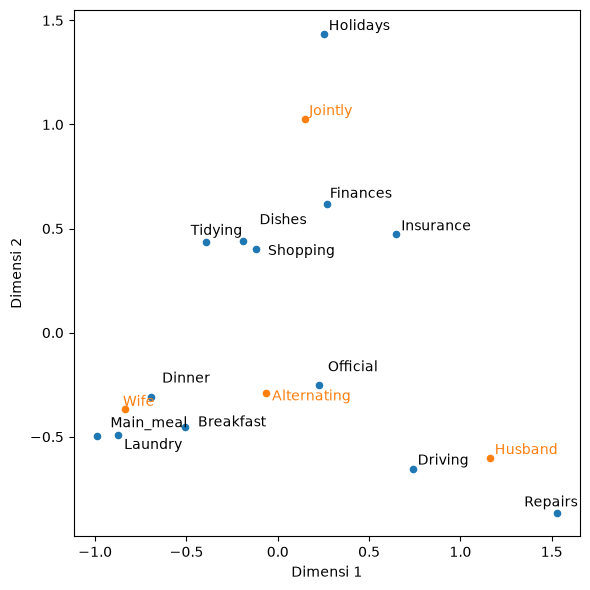

In [12]:
housetasks = pd.read_csv(HOUSE_TASKS_CSV, index_col=0)
print(housetasks)

ca = prince.CA(n_components=2)
ca = ca.fit(housetasks)

row_coord = ca.row_coordinates(housetasks)
col_coord = ca.column_coordinates(housetasks)

ax = row_coord.plot.scatter(x=0, y=1, figsize=(6, 6))
col_coord.plot.scatter(x=0, y=1, ax=ax, c='C1')
texts = []
for idx, row in row_coord.iterrows():
    texts.append(plt.text(row.iloc[0], row.iloc[1], idx))
for idx, row in col_coord.iterrows():
    texts.append(plt.text(row.iloc[0], row.iloc[1], idx, color='C1'))
adjust_text(texts, only_move={'points': 'y', 'texts': 'y'})
ax.set_xlabel('Dimensi 1')
ax.set_ylabel('Dimensi 2')
plt.tight_layout()
plt.show()

In [13]:
# Ringkasan inersia (varians) tiap dimensi dan koordinat kolom
print(ca.eigenvalues_summary)
print('\nKoordinat kolom:')
print(col_coord.round(3))

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.543        48.69%                     48.69%
1              0.445        39.91%                     88.60%

Koordinat kolom:
                 0      1
Wife        -0.838 -0.365
Alternating -0.062 -0.292
Husband      1.161 -0.602
Jointly      0.149  1.027


**Interpretasi:** Dua dimensi CA menjelaskan **88.6%** total inersia (dimensi 1: 48.7%, dimensi 2: 39.9%), sehingga biplot 2D sudah merangkum hampir seluruh asosiasi dalam tabel. Pola yang terlihat:
- **Dimensi 1** memisahkan **Wife** (−0.84) dari **Husband** (1.16). Tugas *Laundry*, *Main_meal*, *Dinner*, dan *Breakfast* berada dekat *Wife* (misalnya Laundry: 156 dari 176 dikerjakan istri), sedangkan *Repairs* dan *Driving* berada dekat *Husband* (Repairs: 160 dari 165).
- **Dimensi 2** memisahkan **Jointly** (1.03) dari yang lain. *Holidays* berada paling atas (153 dari 160 dikerjakan bersama), diikuti *Finances* dan *Insurance*.
- *Tidying*, *Dishes*, dan *Shopping* berada di tengah, antara Wife dan Jointly, karena dikerjakan istri maupun bersama. *Official* berada dekat **Alternating** (−0.06, −0.29), kategori yang dekat titik asal (profilnya mendekati rata-rata).

Jadi CA dengan jelas mengungkap pembagian peran tugas rumah tangga dari tabel 13×4 dalam satu gambar.

## 7.2 K-Means Clustering

**Teori:** *Clustering* adalah teknik untuk membagi data ke dalam kelompok-kelompok berbeda, di mana record dalam satu kelompok mirip satu sama lain. **K-means** adalah metode clustering pertama yang dikembangkan dan masih yang paling populer, karena sederhana dan dapat diskalakan ke data besar.

Istilah kunci:
- **Cluster**: kelompok record yang mirip.
- **Cluster mean / centroid**: vektor rata-rata variabel untuk record dalam satu cluster.
- **K**: jumlah cluster.

K-means membagi data menjadi $K$ cluster dengan meminimalkan **jumlah kuadrat jarak** setiap record ke **mean** cluster-nya (disebut *within-cluster sum of squares*, di `scikit-learn` disebut `inertia_`). Untuk record $x_i$ di cluster $C_k$ dengan mean $\bar{x}_k$:
$$SS_k = \sum_{i \in C_k} \sum_{j=1}^{p} (x_{ij} - \bar{x}_{kj})^2, \qquad \text{minimalkan } \sum_{k=1}^{K} SS_k .$$
K-means **tidak menjamin** ukuran cluster sama, tetapi menghasilkan cluster yang terpisah sebaik mungkin. Karena berbasis jarak Euclidean, variabel biasanya perlu **dinormalisasi** (lihat 7.5).

### 7.2.1 A Simple Example

**Teori:** Contoh sederhana memakai dua variabel (return XOM dan CVX sejak 2011) dan $K=4$. Setiap hari diberi label cluster 0–3. Karena hanya 2 dimensi, hasilnya mudah divisualisasikan: setiap cluster menempati "wilayah" tertentu pada scatter plot, dan centroid ditampilkan sebagai titik hitam.

Catatan: hasil K-means bergantung pada inisialisasi acak. Notebook ini menambahkan `random_state=1` agar hasil dapat direproduksi (kode resmi tidak menetapkan seed), sehingga nomor cluster bisa berbeda dari buku.

In [14]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']].copy()
kmeans = KMeans(n_clusters=4, n_init='auto', random_state=1).fit(df)
df['cluster'] = kmeans.labels_
print(df.head())

                 XOM       CVX  cluster
2011-01-03  0.736805  0.240681        3
2011-01-04  0.168668 -0.584516        0
2011-01-05  0.026631  0.446985        3
2011-01-06  0.248558 -0.919751        0
2011-01-07  0.337329  0.180511        3


In [15]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=['XOM', 'CVX'])
print(centers)
print('\nUkuran cluster:', {int(k): v for k, v in sorted(Counter(kmeans.labels_).items())})

        XOM       CVX
0 -0.286422 -0.492965
1  1.092072  1.581077
2 -1.123045 -1.718845
3  0.325846  0.449970

Ukuran cluster: {0: 421, 1: 123, 2: 118, 3: 469}


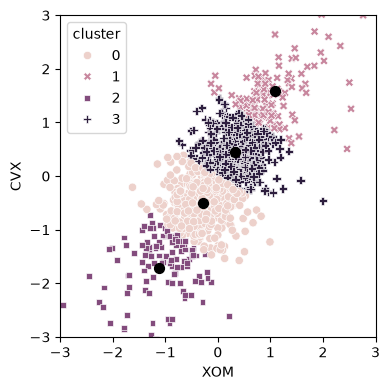

In [16]:
fig, ax = plt.subplots(figsize=(4, 4))
ax = sns.scatterplot(x='XOM', y='CVX', hue='cluster', style='cluster',
                     ax=ax, data=df)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
centers.plot.scatter(x='XOM', y='CVX', ax=ax, s=50, color='black')

plt.tight_layout()
plt.show()

**Interpretasi:** K-means membagi 1.131 hari perdagangan (sejak 2011) ke dalam 4 cluster yang tersusun **sepanjang diagonal** sebaran XOM–CVX:
- Cluster **2** (118 hari, centroid XOM = −1.12, CVX = −1.72): hari ketika kedua saham **turun tajam**.
- Cluster **0** (421 hari, centroid −0.29, −0.49): hari **turun ringan**.
- Cluster **3** (469 hari, centroid 0.33, 0.45): hari **naik ringan**.
- Cluster **1** (123 hari, centroid 1.09, 1.58): hari **naik tajam**.

Karena kedua saham sangat berkorelasi, cluster pada dasarnya mengikuti arah PC1 (pergerakan bersama). Cluster ekstrem (naik/turun tajam) jauh lebih kecil dibanding cluster dekat pusat. Nomor cluster sendiri arbitrer (dapat berbeda dari buku).

### 7.2.2 K-Means Algorithm

**Teori:** Mencari solusi optimal global K-means adalah masalah yang sulit secara komputasi (NP-hard), sehingga dipakai algoritma heuristik yang efisien (algoritma **Lloyd**):
1. Mulai dengan $K$ mean cluster awal (dipilih acak atau dengan *k-means++*, default `scikit-learn`, yang memilih centroid awal saling berjauhan).
2. **Assignment step**: tetapkan setiap record ke cluster dengan mean **terdekat** (jarak Euclidean kuadrat).
3. **Update step**: hitung ulang mean cluster berdasarkan anggota barunya.
4. Ulangi langkah 2–3 sampai penugasan record tidak berubah (konvergen) atau mencapai `max_iter`.

Algoritma ini selalu konvergen, tetapi bisa berhenti di **optimum lokal**. Karena itu algoritma diulang dengan beberapa inisialisasi acak (`n_init`) dan dipilih solusi dengan `inertia_` terkecil. Dengan `n_init='auto'` dan inisialisasi k-means++, `scikit-learn` menjalankan 1 kali; untuk hasil lebih stabil dapat dipakai `n_init=10`.

Di bawah ini K-means diterapkan pada 16 saham (variabel = return tiap saham, record = hari) dengan $K=5$.

In [17]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]
kmeans = KMeans(n_clusters=5, n_init='auto', random_state=1).fit(top_sp)
print('Jumlah iterasi sampai konvergen:', kmeans.n_iter_)
print('Inertia (within-cluster SS)    :', round(kmeans.inertia_, 2))

Jumlah iterasi sampai konvergen: 42
Inertia (within-cluster SS)    : 4756.99


**Interpretasi:** Dengan $K = 5$ pada 16 saham (1.131 hari × 16 variabel), algoritma Lloyd konvergen setelah **42 iterasi** dengan within-cluster sum of squares (`inertia_`) sebesar **4756.99**. Karena `n_init='auto'` dengan k-means++ hanya menjalankan satu inisialisasi, nilai ini bisa sedikit berbeda untuk `random_state` lain. Bila ingin solusi lebih stabil, gunakan `n_init` yang lebih besar.

### 7.2.3 Interpreting the Clusters

**Teori:** Dua hal penting saat menafsirkan cluster:
1. **Ukuran cluster**: berapa record di tiap cluster. Cluster yang sangat tidak seimbang bisa menandakan *outlier* yang jauh atau kelompok kecil yang sangat berbeda (tidak selalu buruk).
2. **Profil centroid**: nilai rata-rata tiap variabel di tiap cluster. Untuk data saham, centroid menunjukkan pola return rata-rata di hari-hari dalam cluster itu, misalnya "hari pasar naik", "hari pasar turun", atau "hari saham energi turun sementara saham lain naik".

Plot centroid mirip dengan plot loadings PCA, tetapi berbeda makna: PCA mencari **arah variasi**, sedangkan centroid K-means menunjukkan **lokasi kelompok**. Meski begitu, sering keduanya menampilkan pola serupa (misalnya kontras sektor energi vs non-energi).

In [18]:
print(Counter(kmeans.labels_))

Counter({np.int32(4): 322, np.int32(1): 271, np.int32(0): 256, np.int32(3): 152, np.int32(2): 130})


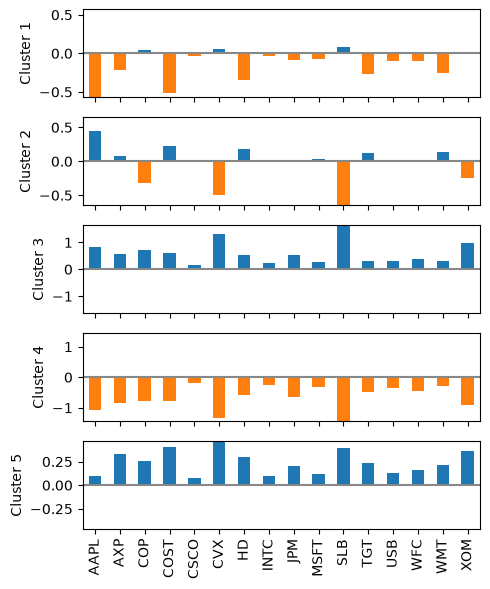

   AAPL   AXP   COP  COST  CSCO   CVX    HD  INTC   JPM  MSFT   SLB   TGT  \
0 -0.57 -0.22  0.04 -0.51 -0.04  0.05 -0.35 -0.04 -0.09 -0.07  0.08 -0.27   
1  0.45  0.08 -0.31  0.23  0.02 -0.49  0.18  0.03  0.02  0.04 -0.64  0.13   
2  0.81  0.55  0.73  0.61  0.17  1.30  0.53  0.23  0.52  0.28  1.62  0.31   
3 -1.08 -0.83 -0.79 -0.77 -0.20 -1.33 -0.58 -0.24 -0.66 -0.33 -1.43 -0.48   
4  0.10  0.34  0.26  0.40  0.07  0.46  0.30  0.10  0.20  0.12  0.39  0.24   

    USB   WFC   WMT   XOM  
0 -0.10 -0.10 -0.26 -0.01  
1  0.03  0.01  0.14 -0.25  
2  0.32  0.39  0.31  0.97  
3 -0.35 -0.46 -0.28 -0.92  
4  0.13  0.17  0.22  0.36  


In [19]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=syms)

f, axes = plt.subplots(5, 1, figsize=(5, 6), sharex=True)
for i, ax in enumerate(axes):
    center = centers.loc[i, :]
    maxPC = 1.01 * np.max(np.abs(center))
    colors = ['C0' if l > 0 else 'C1' for l in center]
    ax.axhline(color='#888888')
    center.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'Cluster {i + 1}')
    ax.set_ylim(-maxPC, maxPC)

plt.tight_layout()
plt.show()

print(centers.round(2))

**Interpretasi:** Ukuran cluster cukup seimbang: 322, 271, 256, 152, dan 130 hari. Profil centroid (bar plot "Cluster 1–5" berurutan untuk label 0–4):
- **Cluster 3 (label 2, 130 hari)**: semua centroid **positif besar** (SLB 1.62, CVX 1.30, XOM 0.97), yaitu hari **pasar naik kuat**, terutama saham energi.
- **Cluster 4 (label 3, 152 hari)**: semua **negatif besar** (SLB −1.43, CVX −1.33, AAPL −1.08), yaitu hari **pasar turun kuat**.
- **Cluster 5 (label 4, 322 hari)**: semua positif kecil (0.07–0.46), yaitu hari **naik ringan**.
- **Cluster 2 (label 1, 271 hari)**: saham **energi negatif** (SLB −0.64, CVX −0.49, COP −0.31, XOM −0.25) sementara AAPL (0.45), COST, dan HD positif, yaitu hari **energi turun tetapi pasar lain naik**.
- **Cluster 1 (label 0, 256 hari)**: kebalikannya: saham non-energi turun (AAPL −0.57, COST −0.51, HD −0.35) sementara energi sedikit positif/datar.

Pola cluster 1 dan 2 serupa dengan kontras **energi vs non-energi** pada PC2 di analisis PCA.

### 7.2.4 Selecting the Number of Clusters

**Teori:** K-means membutuhkan $K$ ditentukan di awal. Kadang $K$ ditentukan oleh kebutuhan aplikasi (misalnya tim pemasaran hanya mampu mengelola 5 segmen pelanggan). Bila tidak, ada pendekatan statistik:
- **Elbow method**: hitung ukuran sebaran dalam cluster (misalnya rata-rata jarak kuadrat / *within-cluster SS*) untuk berbagai $K$, lalu plot. Penambahan cluster selalu menurunkan within-SS, tetapi pada titik tertentu penurunannya melambat drastis ("siku"). $K$ di siku dianggap cukup menangkap struktur data; cluster tambahan hanya memecah cluster yang sudah ada.
- Alternatif: **gap statistic**, **silhouette score**, atau cross-validation (untuk data *holdout*, apakah cluster tetap stabil?).

Pada data nyata, siku sering **tidak jelas**. Pada akhirnya, pemilihan $K$ juga bergantung pada **interpretabilitas** dan kegunaan praktis. Kode di bawah mengikuti buku: `inertia_` dibagi dengan $K$ dan diplot untuk $K = 2,\dots,14$.

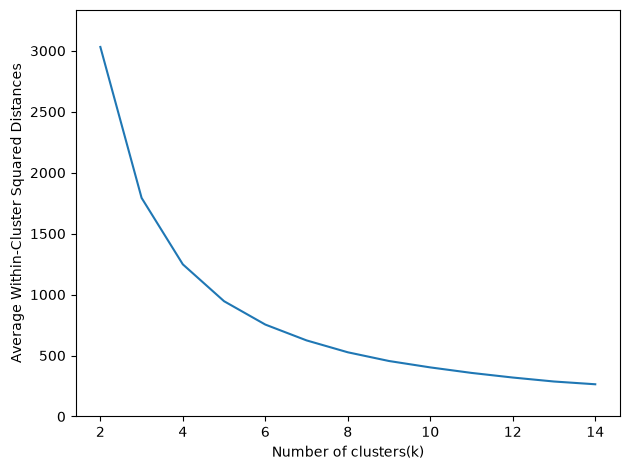

 n_clusters  inertia
          2   3031.8
          3   1793.2
          4   1248.1
          5    945.7
          6    754.1
          7    624.3
          8    526.8
          9    455.2
         10    402.8
         11    357.6
         12    319.6
         13    287.0
         14    264.4


In [20]:
inertia = []
for n_clusters in range(2, 15):
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init='auto').fit(top_sp)
    inertia.append(kmeans.inertia_ / n_clusters)
inertias = pd.DataFrame({'n_clusters': range(2, 15), 'inertia': inertia})
ax = inertias.plot(x='n_clusters', y='inertia')
plt.xlabel('Number of clusters(k)')
plt.ylabel('Average Within-Cluster Squared Distances')
plt.ylim((0, 1.1 * inertias.inertia.max()))
ax.legend().set_visible(False)

plt.tight_layout()
plt.show()

print(inertias.round(1).to_string(index=False))

**Interpretasi:** Rata-rata within-cluster SS (inertia/$K$) turun tajam dari **3031.8** ($K=2$) ke 1793.2 ($K=3$), 1248.1 ($K=4$), dan 945.7 ($K=5$). Setelah itu penurunannya makin landai (754.1 pada $K=6$, 402.8 pada $K=10$, dan 264.4 pada $K=14$). Kurva berbentuk melengkung halus **tanpa siku yang tegas**. Seperti dicatat di buku, ini umum pada data nyata. Siku yang samar ada di sekitar $K = 4$–$6$, sehingga $K=5$ yang dipakai sebelumnya masuk akal. Namun pilihan akhir lebih tepat didasarkan pada interpretabilitas cluster.

## 7.3 Hierarchical Clustering

**Teori:** *Hierarchical clustering* adalah alternatif K-means yang menghasilkan cluster sangat berbeda. Kelebihannya:
- Lebih fleksibel: dapat memakai **ukuran jarak apa pun**, termasuk untuk variabel non-numerik.
- **Tidak perlu menentukan $K$ di awal**; hasilnya berupa hierarki lengkap yang dapat "dipotong" di level mana saja.
- Sangat baik untuk **visualisasi** (*dendrogram*) dan lebih sensitif dalam menemukan outlier atau kelompok aberan.

Kekurangannya: biaya komputasi tinggi ($O(n^2)$ memori untuk matriks jarak, dan waktu $O(n^2)$ hingga $O(n^3)$), sehingga kurang cocok untuk jutaan record. Hierarchical clustering umumnya dipakai untuk data berukuran kecil hingga sedang.

Istilah kunci:
- **Dendrogram**: representasi visual record dan hierarki cluster tempat record tersebut berada.
- **Distance**: ukuran seberapa dekat satu *record* dengan record lain.
- **Dissimilarity**: ukuran seberapa dekat satu *cluster* dengan cluster lain.

### 7.3.1 A Simple Example

**Teori:** Kali ini yang di-cluster adalah **saham** (bukan hari). Karena itu data ditranspos: setiap baris adalah satu saham dan kolomnya adalah return harian sejak 2011 (18 saham, termasuk GOOGL dan AMZN). Fungsi `scipy.cluster.hierarchy.linkage` menghitung hierarki dengan metode **complete linkage**. Hasilnya adalah *linkage matrix* $Z$ berukuran $(n-1) \times 4$: setiap baris mencatat dua cluster yang digabung, jarak penggabungan, dan jumlah anggota cluster baru.

In [21]:
syms1 = ['AAPL', 'AMZN', 'AXP', 'COP', 'COST', 'CSCO', 'CVX', 'GOOGL', 'HD',
         'INTC', 'JPM', 'MSFT', 'SLB', 'TGT', 'USB', 'WFC', 'WMT', 'XOM']
df = sp500_px.loc[sp500_px.index >= '2011-01-01', syms1].transpose()

Z = linkage(df, method='complete')
print(Z.shape)
print(pd.DataFrame(Z[:5], columns=['cluster_a', 'cluster_b', 'jarak', 'n_anggota']).round(2))

(17, 4)
   cluster_a  cluster_b  jarak  n_anggota
0       14.0       15.0   8.59        2.0
1        5.0        9.0   8.71        2.0
2       11.0       19.0  11.44        3.0
3       18.0       20.0  13.54        5.0
4       10.0       21.0  17.54        6.0


**Interpretasi:** Untuk 18 saham, linkage matrix berukuran **(17, 4)**, yaitu 17 langkah penggabungan (dari 18 cluster tunggal menjadi 1). Penggabungan pertama terjadi antara saham indeks 14 dan 15 (**USB** dan **WFC**, dua bank) pada jarak **8.59**, lalu indeks 5 dan 9 (**CSCO** dan **INTC**, dua saham teknologi) pada jarak 8.71. Saham dari sektor yang sama memang bergerak paling mirip. Indeks ≥ 18 pada kolom cluster merujuk ke cluster hasil penggabungan sebelumnya.

### 7.3.2 The Dendrogram

**Teori:** **Dendrogram** adalah diagram pohon yang menampilkan urutan penggabungan cluster. Daun pohon adalah record (di sini saham). **Tinggi** cabang menunjukkan **dissimilarity** saat dua cluster digabung: semakin rendah titik penggabungan, semakin mirip kedua cluster.

Untuk memperoleh sejumlah cluster tertentu, dendrogram "dipotong" secara horizontal. Fungsi `fcluster(Z, 4, criterion='maxclust')` memotong pohon sehingga diperoleh paling banyak 4 cluster.

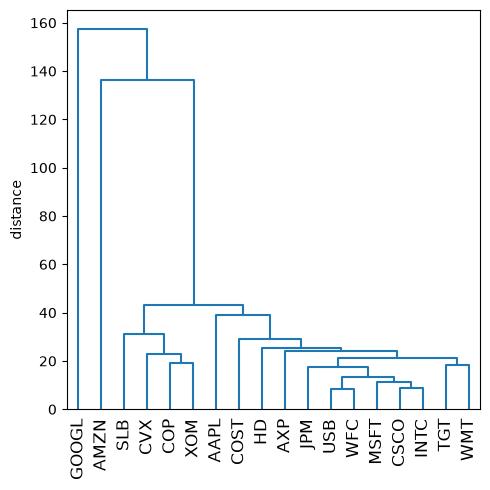

In [22]:
fig, ax = plt.subplots(figsize=(5, 5))
dendrogram(Z, labels=list(df.index), color_threshold=0)
plt.xticks(rotation=90)
ax.set_ylabel('distance')

plt.tight_layout()
plt.show()

In [23]:
memb = fcluster(Z, 4, criterion='maxclust')
memb = pd.Series(memb, index=df.index)
for key, item in memb.groupby(memb):
    print(f"{key} : {', '.join(item.index)}")

1 : COP, CVX, SLB, XOM
2 : AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
3 : AMZN
4 : GOOGL


**Interpretasi:** Dendrogram menunjukkan bahwa **GOOGL** dan **AMZN** sangat berbeda dari saham lain: keduanya baru bergabung pada jarak sekitar 136 dan 157, jauh di atas penggabungan lain (< 45). Penyebabnya adalah perubahan harga harian (dalam dolar) kedua saham ini jauh lebih besar (lihat 7.5.2). Di bagian bawah, saham energi (**XOM, COP, CVX, SLB**) membentuk satu kelompok, sementara saham teknologi, keuangan, dan ritel membentuk kelompok lain. Contohnya pasangan USB–WFC dan CSCO–INTC yang bergabung pada jarak rendah (sekitar 9). Pemotongan menjadi 4 cluster menghasilkan:
1. Energi: COP, CVX, SLB, XOM
2. Sisanya (12 saham teknologi/keuangan/ritel): AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
3. AMZN (sendiri)
4. GOOGL (sendiri)

Hasil ini sama dengan buku: dua saham dengan volatilitas dolar tinggi menjadi cluster tunggal.

### 7.3.3 The Agglomerative Algorithm

**Teori:** Algoritma utama hierarchical clustering adalah **agglomerative** (*bottom-up*): mulai dari cluster beranggotakan satu record, lalu secara iteratif menggabungkan cluster paling mirip.
1. Buat himpunan cluster awal; setiap cluster berisi satu record.
2. Hitung **dissimilarity** $D(C_k, C_\ell)$ antara semua pasangan cluster $k, \ell$.
3. Gabungkan dua cluster $C_k$ dan $C_\ell$ dengan dissimilarity terkecil.
4. Jika masih ada lebih dari satu cluster, kembali ke langkah 2. Jika tidak, selesai.

Jarak antar **record** biasanya Euclidean: $d(x, y) = \sqrt{\sum_j (x_j - y_j)^2}$. Dissimilarity antar **cluster** didefinisikan dengan *linkage* (lihat 7.3.4). Misalnya pada **complete linkage**:
$$D(A, B) = \max_{a \in A,\, b \in B} d(a, b).$$
Sel kode berikut mengimplementasikan algoritma ini secara manual (naif, $O(n^3)$) pada 18 saham dan membandingkan jarak penggabungannya dengan hasil `scipy`.

In [24]:
def agglomerative_complete(X):
    # Implementasi naif agglomerative clustering dengan complete linkage
    X = np.asarray(X, dtype=float)
    d = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))  # jarak antar record
    clusters = {i: [i] for i in range(len(X))}
    heights = []
    while len(clusters) > 1:
        keys = list(clusters)
        best = None
        for a in range(len(keys)):
            for b in range(a + 1, len(keys)):
                ia, ib = clusters[keys[a]], clusters[keys[b]]
                diss = d[np.ix_(ia, ib)].max()          # complete linkage
                if best is None or diss < best[0]:
                    best = (diss, keys[a], keys[b])
        diss, ka, kb = best
        clusters[ka] = clusters[ka] + clusters.pop(kb)  # gabungkan dua cluster
        heights.append(diss)
    return np.array(heights)

manual_heights = agglomerative_complete(df)
print('Jarak penggabungan (manual):', manual_heights.round(2))
print('Jarak penggabungan (scipy) :', Z[:, 2].round(2))
print('Sama?', np.allclose(np.sort(manual_heights), np.sort(Z[:, 2])))

Jarak penggabungan (manual): [  8.59   8.71  11.44  13.54  17.54  18.31  18.96  21.32  22.86  24.03
  25.5   29.19  31.15  38.98  43.24 136.34 157.42]
Jarak penggabungan (scipy) : [  8.59   8.71  11.44  13.54  17.54  18.31  18.96  21.32  22.86  24.03
  25.5   29.19  31.15  38.98  43.24 136.34 157.42]
Sama? True


**Interpretasi:** Implementasi manual algoritma agglomerative dengan complete linkage menghasilkan 17 jarak penggabungan yang **identik** dengan `scipy` (8.59, 8.71, 11.44, …, 43.24, 136.34, 157.42; `Sama? True`). Ini mengonfirmasi bahwa `linkage(method='complete')` mengikuti algoritma 4 langkah di atas. Lonjakan besar dari 43.24 ke 136.34 menandakan dua penggabungan terakhir (dengan AMZN dan GOOGL) menyatukan kelompok yang sangat berbeda. Lonjakan seperti ini adalah tempat alami untuk "memotong" dendrogram.

### 7.3.4 Measures of Dissimilarity

**Teori:** Ada beberapa ukuran dissimilarity (*linkage*) antar cluster $A$ dan $B$:
- **Complete linkage**: jarak **maksimum** antar pasangan record, $\max d(a,b)$. Cenderung menghasilkan cluster dengan anggota yang mirip dan berukuran relatif seimbang.
- **Single linkage**: jarak **minimum**, $\min d(a,b)$. Metode "rakus" yang bisa menghasilkan cluster memanjang (*chaining*) dengan elemen yang sangat berbeda.
- **Average linkage**: **rata-rata** semua jarak antar pasangan; kompromi antara single dan complete.
- **Minimum variance / Ward's method**: menggabungkan dua cluster yang menghasilkan **kenaikan within-cluster sum of squares** terkecil, mirip dengan K-means:
$$\Delta(A,B) = \frac{|A||B|}{|A|+|B|}\,\lVert \bar{x}_A - \bar{x}_B \rVert^2 .$$

Plot di bawah membandingkan keempat metode pada data XOM/CVX dengan pemotongan 4 cluster.

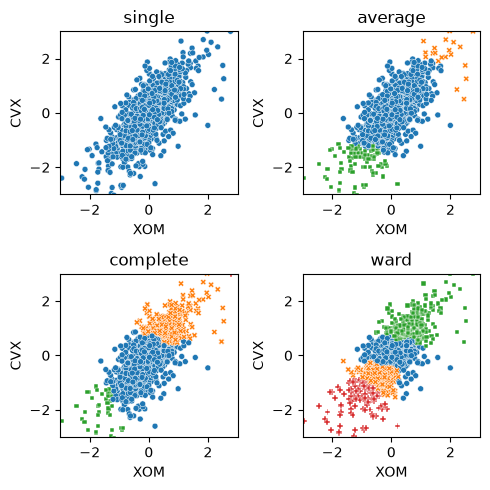

  single: ukuran cluster = [1127, 2, 1, 1]
 average: ukuran cluster = [1015, 91, 24, 1]
complete: ukuran cluster = [805, 277, 44, 5]
    ward: ukuran cluster = [464, 290, 254, 123]


In [25]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(5, 5))
sizes = {}
for i, method in enumerate(['single', 'average', 'complete', 'ward']):
    ax = axes[i // 2, i % 2]
    Z = linkage(df, method=method)
    memb4 = fcluster(Z, 4, criterion='maxclust')
    sizes[method] = sorted(Counter(memb4).values(), reverse=True)
    colors = [f'C{c+1}' for c in memb4]
    ax = sns.scatterplot(x='XOM', y='CVX', hue=colors, style=colors,
                         size=0.5, ax=ax, data=df, legend=False)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(method)

plt.tight_layout()
plt.show()

for method, s in sizes.items():
    print(f'{method:>8}: ukuran cluster = {s}')

**Interpretasi:** Keempat metode menghasilkan cluster yang sangat berbeda pada data XOM/CVX yang sama (1.131 hari):
- **single**: ukuran cluster **[1127, 2, 1, 1]**, hampir semua titik masuk satu cluster dan sisanya hanya outlier. Ini akibat efek *chaining*.
- **average**: [1015, 91, 24, 1], satu cluster besar di tengah dan beberapa cluster di ujung-ujung diagonal (hari ekstrem naik/turun).
- **complete**: [805, 277, 44, 5], lebih seimbang dan memisahkan kelompok hari naik, turun, dan ekstrem.
- **ward**: [464, 290, 254, 123], paling seimbang dan menyerupai K-means (cluster berurutan sepanjang diagonal), karena keduanya meminimalkan within-cluster SS.

Pilihan linkage sangat memengaruhi hasil: single/average berguna untuk mendeteksi outlier, sedangkan complete/ward menghasilkan cluster yang kompak.

## 7.4 Model-Based Clustering

**Teori:** Metode clustering seperti hierarchical dan K-means bersifat **heuristik** dan bergantung pada jarak antar record. **Model-based clustering** berbasis teori statistik dan memberi cara yang lebih ketat untuk menentukan sifat dan jumlah cluster. Ini berguna, misalnya, bila ada kelompok record yang mirip satu sama lain tetapi tidak harus berdekatan (misalnya saham teknologi dengan variansi return tinggi), dan kelompok lain yang mirip dan berdekatan (misalnya saham utilitas dengan variansi rendah).

Pendekatan paling umum mengasumsikan data berasal dari **campuran distribusi normal multivariat**.

### 7.4.1 Multivariate Normal Distribution

**Teori:** Distribusi normal multivariat adalah generalisasi distribusi normal ke $p$ variabel $X_1, \dots, X_p$. Distribusi ini ditentukan oleh vektor mean $\mu$ dan **matriks kovarians** $\Sigma$ (simetris, berisi varians di diagonal dan kovarians di luar diagonal):
$$X \sim N_p(\mu, \Sigma), \qquad f(x) = \frac{1}{(2\pi)^{p/2} |\Sigma|^{1/2}} \exp\!\left(-\tfrac{1}{2}(x-\mu)^\top \Sigma^{-1} (x-\mu)\right).$$
Kontur densitasnya berbentuk **elips**; $\Sigma$ menentukan orientasi dan bentuk elips tersebut.

Contoh buku: $\mu = (0.5, -0.5)$ dan
$$\Sigma = \begin{pmatrix} 1 & 1 \\ 1 & 2 \end{pmatrix}.$$
Kovarians positif membuat elips miring ke arah kanan atas. Garis kontur hitam menandai level probabilitas (kode resmi memakai rumus level sederhana untuk 50%, 75%, 95%, dan 99%).

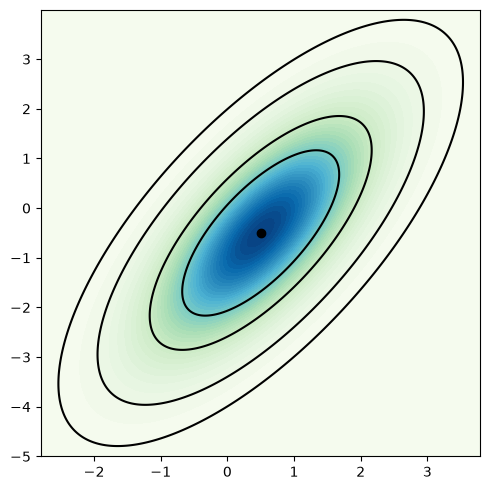

Determinan Sigma: 1.0 | korelasi = 0.707


In [26]:
mean = [0.5, -0.5]
cov = [[1, 1], [1, 2]]
probability = [.5, .75, .95, .99]
def probLevel(p):
    D = 1
    return (1 - p) / (2 * math.pi * D)
levels = [probLevel(p) for p in probability]

fig, ax = plt.subplots(figsize=(5, 5))

x, y = np.mgrid[-2.8:3.8:.01, -5:4:.01]
pos = np.empty(x.shape + (2,))
pos[:, :, 0] = x; pos[:, :, 1] = y
rv = multivariate_normal(mean, cov)

CS = ax.contourf(x, y, rv.pdf(pos), cmap=cm.GnBu, levels=50)
ax.contour(x, y, rv.pdf(pos), levels=sorted(levels), colors=['black'])  # level harus urut naik
ax.plot(*mean, color='black', marker='o')

plt.tight_layout()
plt.show()
print('Determinan Sigma:', np.linalg.det(cov), '| korelasi =', round(1 / math.sqrt(2), 3))

**Interpretasi:** Plot kontur menunjukkan densitas normal bivariat dengan pusat di $\mu = (0.5, -0.5)$ (titik hitam). Kontur berbentuk **elips yang miring** ke kanan atas karena kovariansnya positif ($\sigma_{12} = 1$; korelasi $= 1/\sqrt{1 \cdot 2} \approx 0.707$). Elips juga lebih memanjang pada arah sumbu $y$ karena $\operatorname{Var}(Y) = 2 > \operatorname{Var}(X) = 1$. Determinan $\Sigma$ = 1. Garis kontur hitam (kontur luar = level probabilitas lebih tinggi) membatasi wilayah yang memuat sekitar 50%, 75%, 95%, dan 99% massa probabilitas. Catatan: level kontur harus diurutkan naik untuk Matplotlib versi baru, sehingga dipakai `sorted(levels)`.

### 7.4.2 Mixtures of Normals

**Teori:** Ide utama model-based clustering: setiap record diasumsikan berasal dari **salah satu dari $K$ distribusi normal multivariat**, dengan mean $\mu_k$ dan kovarians $\Sigma_k$ yang berbeda-beda. Densitas campurannya:
$$f(x) = \sum_{k=1}^{K} \pi_k\, \phi(x \mid \mu_k, \Sigma_k), \qquad \sum_k \pi_k = 1,$$
dengan $\pi_k$ proporsi (bobot) komponen ke-$k$. Parameter diestimasi dengan algoritma **Expectation–Maximization (EM)**:
- **E-step**: hitung probabilitas (*responsibility*) setiap record berasal dari tiap komponen, $\gamma_{ik} = \pi_k \phi(x_i|\mu_k,\Sigma_k) / \sum_\ell \pi_\ell \phi(x_i|\mu_\ell,\Sigma_\ell)$.
- **M-step**: perbarui $\pi_k, \mu_k, \Sigma_k$ sebagai rata-rata tertimbang dengan bobot $\gamma_{ik}$.
- Ulangi sampai *log-likelihood* konvergen.

Setiap record lalu ditetapkan ke komponen dengan probabilitas terbesar (*soft clustering* yang di-"keraskan"). Di Python dipakai `sklearn.mixture.GaussianMixture`. Berbeda dengan K-means (yang secara implisit mengasumsikan cluster berbentuk bola dengan ukuran sama), GMM dapat menangkap cluster berbentuk **elips** dengan sebaran berbeda, misalnya satu cluster padat di tengah dan satu cluster lebar untuk hari-hari ekstrem.

In [27]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
mclust = GaussianMixture(n_components=2, random_state=1).fit(df)
print('BIC:', mclust.bic(df))

BIC: 4589.92885731864


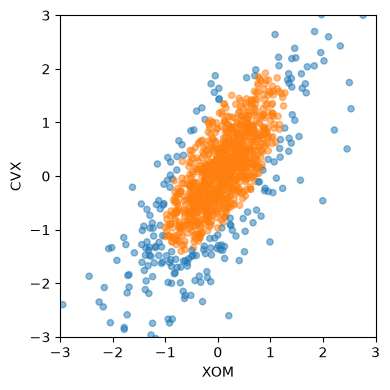

In [28]:
fig, ax = plt.subplots(figsize=(4, 4))
colors = [f'C{c}' for c in mclust.predict(df)]
df.plot.scatter(x='XOM', y='CVX', c=colors, alpha=0.5, ax=ax)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

plt.tight_layout()
plt.show()

In [29]:
print('Weights (pi_k)')
print(mclust.weights_.round(3))
print('Mean')
print(mclust.means_)
print('Covariances')
print(mclust.covariances_)
print('Ukuran cluster:', {int(k): v for k, v in sorted(Counter(mclust.predict(df)).items())})

Weights (pi_k)
[0.345 0.655]
Mean
[[-0.05031426 -0.21161823]
 [ 0.07246995  0.10494619]]
Covariances
[[[0.97123064 0.97764343]
  [0.97764343 1.67233845]]

 [[0.26822676 0.27562091]
  [0.27562091 0.51679853]]]
Ukuran cluster: {0: 215, 1: 916}


**Interpretasi:** GMM dengan 2 komponen pada data XOM/CVX menghasilkan BIC = **4589.93**. Kedua komponen memiliki mean hampir sama dan mendekati nol: (−0.05, −0.21) dan (0.07, 0.10). Perbedaan utamanya ada pada **kovarians**:
- Komponen dengan bobot **0.655** (916 hari) memiliki varians kecil (XOM 0.27, CVX 0.52), yaitu hari-hari **"normal"** yang padat di tengah.
- Komponen dengan bobot **0.345** (215 hari) memiliki varians jauh lebih besar (XOM 0.97, CVX 1.67), yaitu hari-hari **volatil/ekstrem** yang tersebar di pinggir.

Jadi berbeda dengan K-means yang memotong data berdasarkan lokasi, model-based clustering di sini memisahkan data berdasarkan **sebaran (volatilitas)**: satu distribusi sempit di dalam distribusi yang lebih lebar. Pada scatter plot terlihat inti padat berwarna satu dan "halo" titik-titik di luar berwarna lain. Hasil ini sesuai dengan buku.

### 7.4.3 Selecting the Number of Clusters

**Teori:** Kelebihan model-based clustering adalah jumlah cluster dapat dipilih secara otomatis dengan **Bayesian Information Criterion (BIC)**:
$$\text{BIC} = -2 \ln \hat{L} + d \ln n,$$
dengan $\hat L$ likelihood maksimum, $d$ jumlah parameter, dan $n$ jumlah record. BIC menyeimbangkan kecocokan model dengan kompleksitasnya; model dengan BIC **terkecil** yang dipilih (di `scikit-learn` BIC didefinisikan sehingga *lebih kecil = lebih baik*; di paket R `mclust` tandanya dibalik sehingga yang dicari adalah yang terbesar).

Selain $K$, kita juga memilih struktur matriks kovarians (`covariance_type`):
- **full**: setiap komponen punya matriks kovarians sendiri yang bebas (paling fleksibel, parameter terbanyak).
- **tied**: semua komponen berbagi satu matriks kovarians yang sama.
- **diag**: setiap komponen punya kovarians diagonal (variabel tidak berkorelasi dalam komponen; elips sejajar sumbu).
- **spherical**: setiap komponen punya satu varians saja (bola), paling mirip K-means.

Kode di bawah menghitung BIC untuk $K=1..8$ dan keempat tipe kovarians (ditambah `random_state` agar dapat direproduksi).

**Keterbatasan:** model-based clustering mengasumsikan bentuk distribusi tertentu (normal), membutuhkan komputasi lebih berat, dan sulit diskalakan ke data sangat besar atau berdimensi tinggi.

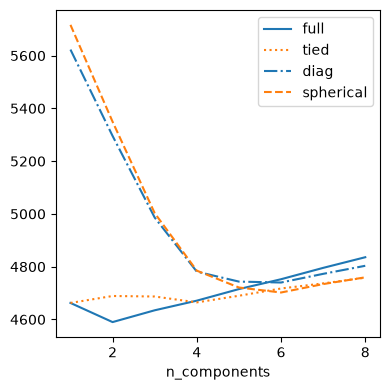

covariance_type    diag    full  spherical    tied
n_components                                      
1                5623.0  4662.5     5716.7  4662.5
2                5295.7  4589.9     5349.6  4688.8
3                4986.2  4634.6     5002.9  4686.9
4                4781.2  4671.1     4784.9  4664.6
5                4743.4  4715.0     4721.0  4689.7
6                4739.9  4752.4     4702.0  4717.3
7                4772.8  4795.4     4734.0  4736.6
8                4803.4  4835.8     4759.6  4758.2

Model dengan BIC terkecil: {'bic': 4589.92885731864, 'n_components': 2, 'covariance_type': 'full'}


In [30]:
results = []
covariance_types = ['full', 'tied', 'diag', 'spherical']
for n_components in range(1, 9):
    for covariance_type in covariance_types:
        mclust = GaussianMixture(n_components=n_components, warm_start=True,
                                 covariance_type=covariance_type, random_state=1)
        mclust.fit(df)
        results.append({
            'bic': mclust.bic(df),
            'n_components': n_components,
            'covariance_type': covariance_type,
        })

results = pd.DataFrame(results)

styles = ['C0-', 'C1:', 'C0-.', 'C1--']

fig, ax = plt.subplots(figsize=(4, 4))
for i, covariance_type in enumerate(covariance_types):
    subset = results.loc[results.covariance_type == covariance_type, :]
    subset.plot(x='n_components', y='bic', ax=ax, label=covariance_type,
                kind='line', style=styles[i])

plt.tight_layout()
plt.show()

print(results.pivot(index='n_components', columns='covariance_type', values='bic').round(1))
best = results.loc[results.bic.idxmin()]
print('\nModel dengan BIC terkecil:', best.to_dict())

**Interpretasi:** BIC terkecil (terbaik menurut definisi `scikit-learn`) adalah **4589.9** untuk model **full** dengan **2 komponen**, yaitu model yang dipakai pada 7.4.2. Pola per tipe kovarians:
- **full**: minimum pada $K=2$, lalu BIC naik lagi (4634.6 pada $K=3$, 4835.8 pada $K=8$) karena penalti parameter.
- **tied**: minimum 4662.5 pada $K=1$ (dengan $K=1$, tied identik dengan full).
- **diag** dan **spherical**: BIC sangat tinggi untuk $K$ kecil (5623 dan 5717 pada $K=1$) karena tidak dapat menangkap korelasi kuat XOM–CVX. Model ini perlu banyak komponen (minimum sekitar $K=6$: 4739.9 dan 4702.0) untuk "meniru" elips miring dengan beberapa bola atau elips sejajar sumbu.

Buku (memakai `mclust` di R) juga memilih model dengan 2 komponen. Ini menunjukkan BIC berguna untuk memilih **jumlah cluster sekaligus struktur kovarians** secara objektif.

## 7.5 Scaling and Categorical Variables

**Teori:** Teknik unsupervised umumnya mengharuskan data **diskalakan** dengan tepat. Ini berbeda dengan banyak teknik regresi dan klasifikasi, di mana skala tidak terlalu penting (kecuali KNN). Isu yang dibahas di bagian ini:
- **Scaling**: menyamakan skala variabel (standardisasi / z-score).
- **Dominant variables**: variabel dengan varians besar mendominasi PCA / clustering.
- **Data kategorikal**: memerlukan ukuran jarak khusus seperti **Gower's distance**.
- **Data campuran**: masalah saat memakai K-means pada gabungan variabel numerik dan biner.

### 7.5.1 Scaling the Variables

**Teori:** Variabel dengan skala sangat berbeda (misalnya `annual_inc` dalam puluhan ribu dolar vs `open_acc` dalam satuan) akan membuat jarak Euclidean **didominasi** oleh variabel berskala besar. Solusinya adalah **standardisasi** (z-score):
$$z = \frac{x - \bar{x}}{s}.$$
Setelah standardisasi, setiap variabel memiliki mean 0 dan simpangan baku 1, sehingga kontribusinya terhadap jarak setara.

Contoh buku: K-means ($K=4$) pada pinjaman yang *default* memakai 6 variabel numerik, pertama **tanpa** scaling lalu **dengan** scaling (`StandardScaler`). Centroid hasil cluster terstandardisasi dikembalikan ke skala asli dengan `inverse_transform` agar mudah ditafsirkan.

In [31]:
loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data['outcome'] = pd.Categorical(loan_data['outcome'],
                                      categories=['paid off', 'default'],
                                      ordered=True)
defaults = loan_data.loc[loan_data['outcome'] == 'default',]

columns = ['loan_amnt', 'annual_inc', 'revol_bal', 'open_acc',
           'dti', 'revol_util']

df = defaults[columns]
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(kmeans.cluster_centers_, columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print(centers.round(2))

   loan_amnt  annual_inc  revol_bal  open_acc    dti  revol_util   size
0   17809.76    78669.45   18933.41     11.59  17.02       62.18   7906
1   21444.32   148736.06   33152.69     12.38  13.83       63.15   1654
2   24290.91   409746.47   84710.99     13.43   8.15       60.02     88
3   10274.16    41241.21    9950.10      9.48  17.72       57.90  13023

In [32]:
scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print(centers.round(2))

   loan_amnt  annual_inc  revol_bal  open_acc    dti  revol_util  size
0   13484.73    55907.99   16435.80     14.32  24.21       59.46  6244
1   25950.21   116834.14   32945.97     12.40  16.17       66.12  3670
2   10507.28    51117.99   11635.29      7.51  15.93       77.80  7397
3   10324.85    53456.82    6054.82      8.66  11.31       31.00  5360


**Interpretasi:** **Tanpa scaling**, cluster hampir sepenuhnya ditentukan oleh **`annual_inc`** (skala puluhan hingga ratusan ribu) dan sebagian `revol_bal`. Centroid `annual_inc` adalah 41k, 79k, 149k, dan 410k, sementara `open_acc`, `dti`, dan `revol_util` hampir sama di semua cluster (misalnya revol_util 58–63). Ukuran cluster juga sangat timpang: 13.023, 7.906, 1.654, dan hanya **88** peminjam di cluster berpenghasilan sangat tinggi.

**Dengan scaling** (z-score), semua variabel ikut berperan dan cluster lebih seimbang (6.244, 3.670, 7.397, 5.360). Profil cluster juga lebih bermakna:
- Cluster 0: `dti` tinggi (24.2) dan `open_acc` banyak (14.3), yaitu peminjam dengan **beban utang tinggi**.
- Cluster 1: pinjaman besar (26k) dan pendapatan tinggi (117k).
- Cluster 2: `revol_util` sangat tinggi (77.8%), yaitu peminjam yang **memakai hampir seluruh limit kredit**.
- Cluster 3: `revol_util` rendah (31%) dan `revol_bal` kecil (6k).

Standardisasi mencegah satu variabel berskala besar mendominasi jarak.

### 7.5.2 Dominant Variables

**Teori:** Meskipun semua variabel diukur dalam skala yang sama dan akurat mencerminkan kepentingan relatifnya, kadang lebih baik melakukan **re-scaling** agar satu variabel tidak mendominasi. Pada data saham, harga dan volatilitas saham berbeda-beda. Sejak 2005 data mencakup **GOOGL** dan **AMZN**, yang perubahan harga hariannya (dalam dolar) jauh lebih besar daripada saham lain. Akibatnya, PCA (yang bekerja pada kovarians) didominasi kedua saham ini: PC1 dan PC2 hampir seluruhnya merepresentasikan GOOGL dan AMZN.

Solusi: (1) sertakan variabel apa adanya bila memang bermakna, (2) **standardisasi** variabel (PCA pada matriks korelasi), atau (3) keluarkan variabel dominan dan analisis terpisah. Tidak ada jawaban yang selalu benar; tergantung tujuan analisis.

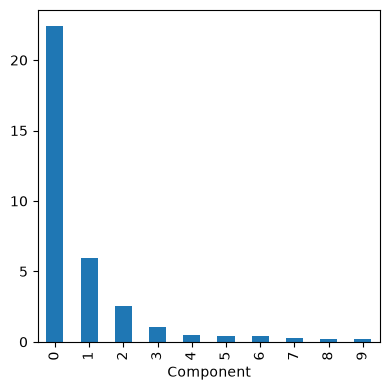

Proporsi varians (3 komponen pertama): [0.647 0.172 0.074]


In [33]:
syms = ['GOOGL', 'AMZN', 'AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM',
        'SLB', 'COP', 'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST']
top_sp1 = sp500_px.loc[sp500_px.index >= '2005-01-01', syms]

sp_pca1 = PCA()
sp_pca1.fit(top_sp1)

explained_variance = pd.DataFrame(sp_pca1.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')

plt.tight_layout()
plt.show()
print('Proporsi varians (3 komponen pertama):', sp_pca1.explained_variance_ratio_[:3].round(3))

In [34]:
loadings = pd.DataFrame(sp_pca1.components_[0:2, :],
                        columns=top_sp1.columns)
print(loadings.transpose().round(3))

           0      1
GOOGL  0.857 -0.478
AMZN   0.445  0.874
AAPL   0.072  0.021
MSFT   0.036  0.006
CSCO   0.029  0.003
INTC   0.027  0.006
CVX    0.090  0.037
XOM    0.080  0.021
SLB    0.110  0.030
COP    0.058  0.024
JPM    0.071  0.009
WFC    0.053  0.009
USB    0.042  0.006
AXP    0.079  0.024
WMT    0.040  0.007
TGT    0.064  0.025
HD     0.051  0.033
COST   0.071  0.034


In [35]:
# Tambahan: varians return tiap saham, dan PCA setelah standardisasi sebagai pembanding
print('Varians return harian (5 terbesar):')
print(top_sp1.var().sort_values(ascending=False).head().round(2))

sp_pca1_std = PCA().fit(preprocessing.StandardScaler().fit_transform(top_sp1))
print('\nPCA terstandardisasi: proporsi varians 3 komponen pertama:',
      sp_pca1_std.explained_variance_ratio_[:3].round(3))

Varians return harian (5 terbesar):
GOOGL    17.93
AMZN      9.07
SLB       1.57
CVX       0.91
XOM       0.73
dtype: float64

PCA terstandardisasi: proporsi varians 3 komponen pertama: [0.446 0.096 0.069]


**Interpretasi:** Dengan data sejak 2005 dan menyertakan GOOGL serta AMZN, **PC1 menjelaskan 64.7%** varians dan PC2 **17.2%**. Loadings menunjukkan PC1 hampir seluruhnya **GOOGL (0.857)** dan **AMZN (0.445)**, sedangkan PC2 adalah kontras **AMZN (0.874) vs GOOGL (−0.478)**. Loadings semua saham lain kecil (≤ 0.11). Penyebabnya terlihat dari varians return harian (dalam dolar): **GOOGL 17.93** dan **AMZN 9.07**, jauh di atas saham lain (SLB 1.57, CVX 0.91). Dua komponen pertama hanya "mencerminkan" kedua saham ini, bukan struktur pasar secara umum.

Sebagai pembanding, PCA setelah **standardisasi** memberi PC1 = 44.6%, PC2 = 9.6%, dan PC3 = 6.9%. Strukturnya kembali mirip analisis 16 saham sebelumnya (faktor pasar dominan) karena kedua saham tidak lagi mendominasi.

### 7.5.3 Categorical Data and Gower's Distance

**Teori:** Untuk data kategorikal, kita bisa mengubahnya menjadi variabel biner (*one-hot encoding*), tetapi bila dicampur dengan variabel numerik, skalanya menjadi tidak sebanding. **Gower's distance** menangani data campuran (numerik dan kategorikal) dengan menerapkan ukuran jarak berbeda per tipe variabel:
- **Numerik / ordinal**: jarak dihitung sebagai selisih absolut yang dinormalisasi dengan rentang variabel,
$$d_{ij}^{(f)} = \frac{|x_{if} - x_{jf}|}{\max(x_f) - \min(x_f)} \in [0,1].$$
- **Kategorikal**: $d_{ij}^{(f)} = 0$ jika kategori sama, $1$ jika berbeda.

Jarak Gower adalah **rata-rata** jarak per variabel:
$$d_{ij} = \frac{1}{p}\sum_{f=1}^{p} d_{ij}^{(f)} \in [0, 1].$$
Matriks jarak ini lalu dapat dipakai untuk **hierarchical clustering** (yang menerima jarak apa pun), tetapi **tidak** untuk K-means (yang memerlukan mean).

Kode resmi Python tidak menyediakan Gower's distance (di buku, contoh ini dikerjakan dengan `daisy()` dari paket R `cluster`). Di notebook ini **Gower's distance diimplementasikan manual dengan NumPy**, lalu contoh R direproduksi: matriks jarak untuk 5 record pertama, kemudian hierarchical clustering (complete linkage) atas sampel 250 pinjaman dan pemotongan dendrogram pada tinggi 0.5.

In [36]:
x = defaults[['dti', 'payment_inc_ratio', 'home_', 'purpose_']].loc[0:4, :]
print(x)

     dti  payment_inc_ratio home_            purpose_
0   1.00            2.39320  RENT      major_purchase
1   5.55            4.57170   OWN      small_business
2  18.08            9.71600  RENT               other
3  10.08           12.21520  RENT  debt_consolidation
4   7.06            3.90888  RENT               other


In [37]:
def gower_distance(data, ranges=None):
    # Matriks jarak Gower (setara daisy(metric='gower') di R)
    data = pd.DataFrame(data)
    n = len(data)
    total = np.zeros((n, n))
    for col in data.columns:
        v = data[col]
        if pd.api.types.is_numeric_dtype(v):
            vals = v.to_numpy(dtype=float)
            rng = (ranges or {}).get(col, vals.max() - vals.min())
            d = np.abs(vals[:, None] - vals[None, :]) / rng if rng > 0 else np.zeros((n, n))
        else:
            vals = v.astype(str).to_numpy()
            d = (vals[:, None] != vals[None, :]).astype(float)
        total += d
    return pd.DataFrame(total / data.shape[1], index=data.index, columns=data.index)

print(gower_distance(x).round(4))

        0       1       2       3       4
0  0.0000  0.6220  0.6864  0.6329  0.3773
1  0.6220  0.0000  0.8143  0.7609  0.5390
2  0.6864  0.8143  0.0000  0.4307  0.3091
3  0.6329  0.7609  0.4307  0.0000  0.5056
4  0.3773  0.5390  0.3091  0.5056  0.0000


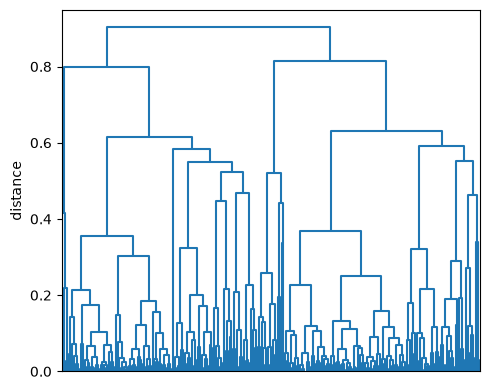

Jumlah cluster pada tinggi 0.5: 12
Ukuran cluster: {1: 4, 2: 62, 3: 23, 4: 12, 5: 15, 6: 1, 7: 12, 8: 4, 9: 73, 10: 20, 11: 15, 12: 9}

Cluster 1 (n=4): home_ = {'RENT': 3, 'OWN': 1}
   purpose_ = {'major_purchase': 4}
   rata-rata dti = 10.10, payment_inc_ratio = 5.95

Cluster 2 (n=62): home_ = {'MORTGAGE': 62}
   purpose_ = {'debt_consolidation': 62}
   rata-rata dti = 16.25, payment_inc_ratio = 7.50

Cluster 3 (n=23): home_ = {'MORTGAGE': 23}
   purpose_ = {'credit_card': 23}
   rata-rata dti = 17.52, payment_inc_ratio = 8.07

Cluster 4 (n=12): home_ = {'MORTGAGE': 12}
   purpose_ = {'small_business': 6, 'major_purchase': 6}
   rata-rata dti = 14.57, payment_inc_ratio = 4.87

Cluster 5 (n=15): home_ = {'MORTGAGE': 15}
   purpose_ = {'home_improvement': 9, 'other': 6}
   rata-rata dti = 15.08, payment_inc_ratio = 5.84

Cluster 6 (n=1): home_ = {'MORTGAGE': 1}
   purpose_ = {'medical': 1}
   rata-rata dti = 33.79, payment_inc_ratio = 10.31

Cluster 7 (n=12): home_ = {'OWN': 12}
   pur

In [38]:
# Hierarchical clustering dengan Gower's distance pada 250 pinjaman acak
gcols = ['dti', 'payment_inc_ratio', 'home_', 'purpose_']
sample = loan_data.sample(250, random_state=301)[gcols]
D = gower_distance(sample)

Zg = linkage(squareform(D.to_numpy(), checks=False), method='complete')

fig, ax = plt.subplots(figsize=(5, 4))
dendrogram(Zg, no_labels=True, color_threshold=0, ax=ax)
ax.set_ylabel('distance')
plt.tight_layout()
plt.show()

# Potong dendrogram pada tinggi 0.5 dan tampilkan cluster-cluster di bawahnya
memb_g = pd.Series(fcluster(Zg, 0.5, criterion='distance'), index=sample.index)
print('Jumlah cluster pada tinggi 0.5:', memb_g.nunique())
print('Ukuran cluster:', {int(k): v for k, v in sorted(Counter(memb_g).items())})
for k in sorted(memb_g.unique()):
    sub = sample.loc[memb_g == k]
    print(f'\nCluster {k} (n={len(sub)}): home_ = {dict(Counter(sub.home_))}')
    print('   purpose_ =', dict(Counter(sub.purpose_)))
    print('   rata-rata dti = %.2f, payment_inc_ratio = %.2f' % (sub.dti.mean(), sub.payment_inc_ratio.mean()))

**Interpretasi:** Matriks jarak Gower untuk 5 pinjaman pertama bernilai antara 0 dan 1. Pasangan **paling mirip** adalah record 2 dan 4 (**0.309**): keduanya `RENT` dengan tujuan `other`, sehingga jarak hanya berasal dari perbedaan `dti` dan `payment_inc_ratio`. Pasangan **paling berbeda** adalah record 1 dan 2 (**0.814**): `home_` dan `purpose_` keduanya berbeda (masing-masing menyumbang 1) dan `dti` juga berselisih jauh (5.55 vs 18.08). Ini menunjukkan bahwa variabel kategorikal menyumbang lompatan besar (1/p = 0.25 per variabel) pada jarak Gower. (Rentang variabel numerik dihitung dari data yang di-cluster, seperti `daisy`, sehingga nilainya bisa sedikit berbeda dari buku.)

Pada hierarchical clustering 250 pinjaman acak, pemotongan pada tinggi 0.5 menghasilkan **12 cluster**. Hampir semua cluster **homogen** pada variabel kategorikal. Contohnya cluster 2 (62 pinjaman, semuanya MORTGAGE + debt_consolidation), cluster 9 (73 pinjaman, semuanya RENT + debt_consolidation), dan cluster 3 (23 pinjaman, MORTGAGE + credit_card). Hasil ini sejalan dengan temuan buku: struktur cluster didominasi oleh kombinasi kategori `home_` dan `purpose_`, sedangkan variabel numerik (dti sekitar 15–19 di kebanyakan cluster) hanya membedakan di dalamnya.

### 7.5.4 Problems with Clustering Mixed Data

**Teori:** K-means dan PCA paling cocok untuk variabel **kontinu**. Untuk data kecil, hierarchical clustering dengan Gower's distance lebih tepat. Pada prinsipnya K-means bisa diterapkan pada variabel biner atau kategorikal (setelah *one-hot encoding* dan standardisasi), tetapi ada masalah: **variabel biner/kategorikal cenderung mendominasi** pembentukan cluster. Setelah distandardisasi, variabel biner hanya mempunyai dua nilai yang berjauhan, sehingga K-means dengan mudah membentuk cluster yang "murni" menurut kategori (misalnya satu cluster semua penyewa rumah). Hasilnya, cluster hanya mencerminkan kategori tersebut dan tidak mengungkap struktur menarik dari variabel numerik.

Solusi: gunakan Gower's distance + hierarchical clustering, kurangi bobot variabel biner, atau gunakan metode khusus seperti **K-prototypes**. Contoh buku memakai `dti`, `payment_inc_ratio`, `home_` (dummy), dan `pub_rec_zero`.

In [39]:
columns = ['dti', 'payment_inc_ratio', 'home_', 'pub_rec_zero']
df = pd.get_dummies(defaults[columns])

scaler = preprocessing.StandardScaler()

df0 = scaler.fit_transform(df * 1.0)
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=df.columns)
centers['size'] = [Counter(kmeans.labels_)[i] for i in range(4)]
print(centers.round(2))

     dti  payment_inc_ratio  pub_rec_zero  home__MORTGAGE  home__OWN  \
0  21.43              12.35          0.94             0.0       -0.0   
1  12.74               5.92          0.90             0.0       -0.0   
2  17.34               8.35          0.91             1.0       -0.0   
3  17.20               9.27          0.92            -0.0        1.0   

   home__RENT  size  
0         1.0  5363  
1         1.0  5641  
2         0.0  9779  
3         0.0  1888  


**Interpretasi:** K-means pada data campuran (setelah one-hot dan standardisasi) menghasilkan cluster yang **ditentukan oleh variabel biner `home_`**. Cluster 0 dan 1 semuanya **RENT** (home__RENT = 1.0), cluster 2 semuanya **MORTGAGE**, dan cluster 3 semuanya **OWN**. Variabel `pub_rec_zero` hampir sama di semua cluster (0.90–0.94). Hanya kelompok penyewa (yang terbesar) yang dibagi lagi berdasarkan variabel numerik: cluster 0 (dti 21.4, payment_inc_ratio 12.4) vs cluster 1 (dti 12.7, rasio 5.9). Ukuran cluster: 5.363, 5.641, 9.779, dan 1.888. Ini mengilustrasikan masalah yang dibahas buku: variabel biner yang distandardisasi mendominasi K-means, sehingga cluster hanya "menemukan kembali" kategori yang sudah diketahui. Nilai `-0.0` pada output hanyalah artefak pembulatan *floating point* (setara 0).

## Ringkasan Chapter 7

1. **Unsupervised learning** mengekstrak struktur dari data tanpa variabel outcome. Tujuannya meliputi reduksi dimensi, clustering, dan eksplorasi data. Hasilnya juga dapat dipakai sebagai input model supervised.
2. **PCA** membentuk kombinasi linear variabel (principal components) yang saling ortogonal dan memaksimalkan varians. Loadings adalah eigenvector matriks kovarians/korelasi. **Screeplot** membantu memilih jumlah komponen, dan **plot loadings** membantu interpretasi (contoh: faktor pasar dan kontras sektor energi pada data saham).
3. **Correspondence Analysis** adalah analog PCA untuk tabel kontingensi kategorikal. Biplot menampilkan asosiasi antar kategori baris dan kolom (contoh: pembagian tugas rumah tangga).
4. **K-means** meminimalkan within-cluster sum of squares dengan algoritma iteratif (assign → update). Hasilnya bergantung pada inisialisasi, dan $K$ dipilih dengan **elbow method** atau pertimbangan praktis/interpretabilitas.
5. **Hierarchical clustering** (agglomerative) tidak memerlukan $K$ di awal dan menghasilkan **dendrogram**. Pilihan **linkage** (single, average, complete, Ward) sangat memengaruhi bentuk cluster. Metode ini fleksibel terhadap ukuran jarak tetapi mahal untuk data besar.
6. **Model-based clustering** mengasumsikan data berasal dari **campuran distribusi normal multivariat** yang diestimasi dengan algoritma EM. Metode ini dapat menangkap cluster dengan bentuk dan sebaran berbeda, dan jumlah cluster serta struktur kovarians dipilih dengan **BIC**.
7. **Scaling** (standardisasi) penting agar variabel berskala besar tidak mendominasi jarak. Variabel dengan varians sangat besar (**dominant variables**, misalnya GOOGL/AMZN) dapat mendominasi PCA dan clustering.
8. Untuk **data campuran**, **Gower's distance** (rata-rata jarak per variabel yang dinormalisasi ke [0,1]) dipakai bersama hierarchical clustering. K-means pada data campuran cenderung didominasi variabel biner/kategorikal.